# Where Typhoon Exposure and Rice-Price Volatility Overlap

## Why this analysis matters

Severe weather warnings and rice prices are both important signals for food-security planning. This project brings them together to identify places that deserve closer attention.

The central question is:

> Which Philippine regions and provinces had both more severe typhoon warnings and larger rice-price increases during 2024-2025?

This is not a prediction model and it is not a causal study. It is a transparent screening analysis: it shows where two patterns overlap, explains how the groups were formed, and identifies practical next questions.

## What this analysis does

- Measures repeated exposure to severe typhoon warnings.
- Measures sudden upward movements in regular-milled rice prices.
- Compares regions and provinces using the same definitions.
- Identifies places for monitoring and deeper investigation.
- Tests whether the broad pattern changes when price readings are sampled monthly.

## How to read the notebook

1. We first establish what the data contain.
2. We define the two measures and why they are appropriate for this question.
3. We describe warnings and prices separately.
4. We combine them into four clear groups.
5. We interpret the results carefully and state what should happen next.

The analysis describes patterns that occurred together. It does **not** claim that typhoons caused rice prices to change.


In [1]:
from pathlib import Path
import sqlite3, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
PROJECT_ROOT=Path.cwd()
while not (PROJECT_ROOT/"data/processed/project.db").exists() and PROJECT_ROOT!=PROJECT_ROOT.parent: PROJECT_ROOT=PROJECT_ROOT.parent
DB=PROJECT_ROOT/"data/processed/project.db"; FIG=PROJECT_ROOT/"output/figures"; FIG.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({"figure.dpi":120,"savefig.dpi":160,"font.size":10})
COL={"Most vulnerable":"#d73027","Exposed but stable":"#4575b4","High price swings, lower severe-warning exposure":"#fdae61","Low concern":"#abd9e9"}
MARK={"Most vulnerable":"o","Exposed but stable":"s","High price swings, lower severe-warning exposure":"^","Low concern":"D"}
BOX=list(COL)
with sqlite3.connect(f"file:{DB}?mode=ro",uri=True) as con:
    signals=pd.read_sql_query("select sid,season,name,issued_time,tcws_1,tcws_2,tcws_3,tcws_4,tcws_5 from province_signals",con)
    boundaries=pd.read_sql_query("select province,region,lat,lon from provincial_boundaries",con)
    prices=pd.read_sql_query("select province,phase,period_start,regular_milled_price from rice_prices",con)
signals.issued_time=pd.to_datetime(signals.issued_time); prices.period_start=pd.to_datetime(prices.period_start)
all_prov=boundaries.province.drop_duplicates().sort_values().tolist()
def split(x): return [] if pd.isna(x) or not str(x).strip() else [p.strip() for p in str(x).split(";") if p.strip()]
parts=[]
for lev in range(1,6):
    d=signals[["sid","season","name","issued_time",f"tcws_{lev}"]].copy(); d["province"]=d[f"tcws_{lev}"].map(split); d=d.explode("province").dropna(subset=["province"]); d["signal_level"]=lev; parts.append(d[["sid","season","name","issued_time","province","signal_level"]])
long=pd.concat(parts,ignore_index=True)
peak=long.groupby(["sid","province"],as_index=False).signal_level.max().rename(columns={"signal_level":"peak_signal"})
exposure=pd.DataFrame({"province":all_prov}).merge(peak.assign(severe=peak.peak_signal>=3).groupby("province").severe.sum().rename("n_severe"),on="province",how="left").fillna({"n_severe":0}).merge(boundaries,on="province")
exposure.n_severe=exposure.n_severe.astype(int)
months=pd.date_range("2024-01-01","2025-12-01",freq="MS")
monthly_warning=long.assign(month=long.issued_time.dt.to_period("M").dt.to_timestamp()).groupby("month").province.nunique().reindex(months,fill_value=0)
pw=prices.sort_values(["province","period_start","phase"])
price_wide=pw.pivot(index="province",columns="period_start",values="regular_milled_price").sort_index(axis=1)
price_wide=price_wide.loc[price_wide.notna().any(axis=1)]
monthly_wide=price_wide.loc[:,price_wide.columns.day==1]
def upside_swing(wide):
    rises=wide.pct_change(axis=1,fill_method=None).mul(100).clip(lower=0).fillna(0)
    return np.sqrt((rises.pow(2).sum(axis=1))/(wide.shape[1]-1))
upside=upside_swing(price_wide).rename("upside_swing")
upside_month=upside_swing(monthly_wide).rename("upside_month")
price_stats=pd.DataFrame({"upside_swing":upside,"upside_month":upside_month})
price_stats["total_change_pct"]=price_wide.apply(lambda r:(r.dropna().iloc[-1]/r.dropna().iloc[0]-1)*100,axis=1)
price_stats["reading_count"]=price_wide.notna().sum(axis=1)
def short(x):
    x=x.split("(",1)[1].split(")",1)[0] if "(" in x and ")" in x else x
    return x.replace(" Region","").replace(" Autonomous","").strip()
for d in (exposure,boundaries): d["region_short"]=d.region.map(short)
prov=exposure.merge(price_stats.reset_index(),on="province",how="inner")
region_exposure=exposure.groupby("region_short").agg(n_provinces=("province","size"),n_severe=("n_severe","median")).reset_index()
reg_prices=prov.groupby("region_short").agg(upside_swing=("upside_swing","median"),upside_month=("upside_month","median")).reset_index()
reg=region_exposure.merge(reg_prices,on="region_short")
def assign_boxes(d,measure):
    x_median=d.n_severe.median(); y_median=d[measure].median(); result=d.copy(); high_x=result.n_severe>x_median; high_y=result[measure]>y_median
    result["box"]=np.select([high_x&high_y,high_x&~high_y,~high_x&high_y],BOX[:3],default=BOX[3])
    return result,x_median,y_median
region_main,region_x_median,region_y_median=assign_boxes(reg,"upside_swing")
region_month,_,region_month_y_median=assign_boxes(reg,"upside_month")
prov_main,province_x_median,province_y_median=assign_boxes(prov,"upside_swing")
prov_month,_,province_month_y_median=assign_boxes(prov,"upside_month")
region_main=region_main.merge(region_month[["region_short","box"]].rename(columns={"box":"month_box"}),on="region_short")
prov_main=prov_main.merge(prov_month[["province","box"]].rename(columns={"box":"month_box"}),on="province")
region_main["robust"]=region_main.month_box.eq("Most vulnerable")
prov_main["robust"]=prov_main.month_box.eq("Most vulnerable")
region_price_counts=prov.groupby("region_short").province.size().rename("price_count")
region_mv_counts=prov_main[prov_main.box.eq("Most vulnerable")].groupby("region_short").province.size().rename("mv_count")
region_shares=region_price_counts.to_frame().join(region_mv_counts,how="left").fillna({"mv_count":0}); region_shares["share"]=region_shares.mv_count.astype(int).astype(str)+"/"+region_shares.price_count.astype(int).astype(str)
def rhythm_share(g):
    z=g.dropna(subset=["regular_milled_price"]).assign(month=lambda x:x.period_start.dt.to_period("M"))
    wide=z.pivot_table(index="month",columns="phase",values="regular_milled_price",aggfunc="first")
    if not {"1st","2nd"}.issubset(wide.columns): return np.nan
    return (wide["1st"].eq(wide["2nd"]) & wide[["1st","2nd"]].notna().all(axis=1)).mean()
rhythm=prices.groupby("province").apply(rhythm_share,include_groups=False)
# Storm timing and repeat-hit calculations use bulletin issue times.
storm_first=signals.groupby("sid")["issued_time"].min().rename("first_bulletin").reset_index(); storm_peak=peak.groupby("sid").peak_signal.max().rename("storm_peak").reset_index(); storms=storm_first.merge(storm_peak,on="sid",how="left").fillna({"storm_peak":0}); storms["month"]=storms.first_bulletin.dt.to_period("M").dt.to_timestamp(); storms["storm_type"]=np.select([storms.storm_peak.eq(0),storms.storm_peak.le(2)],["never warned","Signal 1-2 only"],default="Signal 3+")
storms_by_month=storms.groupby(["month","storm_type"]).size().unstack(fill_value=0).reindex(months,fill_value=0)
for typ in ["never warned","Signal 1-2 only","Signal 3+"]:
    if typ not in storms_by_month: storms_by_month[typ]=0
storms_by_month=storms_by_month[["never warned","Signal 1-2 only","Signal 3+"]]
first_severe=long[long.signal_level>=3].groupby(["sid","province"])["issued_time"].min().reset_index(name="first_severe").sort_values(["province","first_severe","sid"]); first_severe["previous_severe"]=first_severe.groupby("province").first_severe.shift(1); first_severe["repeat_hit"]=(first_severe.first_severe-first_severe.previous_severe).dt.days.le(14).fillna(False)
repeat_counts=first_severe.groupby("province").repeat_hit.sum().astype(int).rename("repeat_hits"); severe_counts=first_severe.groupby("province").size().astype(int).rename("n_severe"); frequent=pd.DataFrame({"n_severe":severe_counts,"repeat_hits":repeat_counts}).fillna(0).reset_index(); frequent=frequent[frequent.n_severe>=4].sort_values(["n_severe","repeat_hits","province"],ascending=[False,False,True])
print("Signals: long rows",len(long),"| expected 2717 |","MATCH" if len(long)==2717 else "DIFFERENT"); print("Provinces ever warned",peak.province.nunique(),"| expected 63 |","MATCH" if peak.province.nunique()==63 else "DIFFERENT"); print("Warned storms",peak.sid.nunique(),"of",signals.sid.nunique(),"| expected 29 of 41"); print("Province-storm pairs",len(peak),"| expected 568 |","MATCH" if len(peak)==568 else "DIFFERENT"); print("Peak counts levels 1..5",peak.peak_signal.value_counts().reindex(range(1,6),fill_value=0).tolist(),"| expected [260, 168, 75, 54, 11]"); print("Storms per month:",int((storms_by_month.sum(axis=1)>0).sum()),"of 24"); print("Repeat hits:",int(first_severe.repeat_hit.sum()),"across",int((repeat_counts>0).sum()),"provinces")
print("Price table shape:",price_wide.shape,"| expected (81, 48)"); print("Missing readings:",int(prices.regular_milled_price.isna().sum()),"in",int(prices.assign(missing=prices.regular_milled_price.isna()).groupby("province").missing.any().sum()),"provinces"); print("Provinces ending lower:",int((price_stats.total_change_pct<0).sum()),"of",len(price_stats)); print("Upside swing median:",round(upside.median(),2),"| monthly:",round(upside_month.median(),2)); print("Upside swing top five:",upside.sort_values(ascending=False).head().round(2).to_dict()); print("Reporting rhythm median/min/max:",round(rhythm.median(),2),round(rhythm.min(),2),round(rhythm.max(),2),"| >=0.9:",int((rhythm>=.9).sum()))

Signals: long rows 2717 | expected 2717 | MATCH
Provinces ever warned 63 | expected 63 | MATCH
Warned storms 29 of 41 | expected 29 of 41
Province-storm pairs 568 | expected 568 | MATCH
Peak counts levels 1..5 [260, 168, 75, 54, 11] | expected [260, 168, 75, 54, 11]
Storms per month: 14 of 24
Repeat hits: 28 across 16 provinces
Price table shape: (81, 48) | expected (81, 48)
Missing readings: 98 in 3 provinces
Provinces ending lower: 75 of 81
Upside swing median: 1.98 | monthly: 2.11
Upside swing top five: {'Masbate': 5.34, 'Batangas': 5.22, 'Marinduque': 4.97, 'Occidental Mindoro': 4.48, 'Aurora': 4.41}
Reporting rhythm median/min/max: 0.38 0.0 0.92 | >=0.9: 3


## 1. Data and analysis scope

We begin by checking the sources, coverage, and analysis population before drawing any conclusions.

The notebook uses:

- **PAGASA warning records** for typhoon exposure;
- **Provincial boundaries** to attach each province to a region; and
- **PSA regular-milled rice prices** for price changes.

The database is opened read-only. The forecast table is not used in this analysis.


# KPI and metric definitions

### 2. Measuring the two signals

The warning data lists provinces separately for Wind Signals 1 to 5. We reshape those lists so that each row represents one province listed in one bulletin.

This prepares the first KPI: the number of storms in which each province reached a severe warning level.


### KPI 1: severe-warning exposure (`n_severe`)

**Definition:** the number of different storms where a province reached Wind Signal 3 or higher.

- A storm is counted once per province, even if it appears in several bulletins.
- Provinces with no severe warning are assigned zero.
- This measures warning exposure, not damage or losses.


### KPI 2: rice-price upside swing

**Definition:** how sharply a province's regular-milled rice price rose between readings.

- Price increases are kept as percentage changes.
- Price decreases and unchanged prices count as zero.
- The increases are combined into one upside-swing score.
- The main analysis uses 48 readings across two years.

A second version uses one reading per month. That version is only a robustness check.


In [2]:
def legend(ax):
    handles=[Line2D([0],[0],marker=MARK[x],color="none",markerfacecolor=COL[x],markeredgecolor="#333",markersize=8,label=x) for x in BOX]
    ax.legend(handles=handles,title="Box",frameon=False,fontsize=8,loc="upper center",bbox_to_anchor=(0.5,-0.13),ncol=2)
def display_x(z):
    x=z.n_severe.astype(float).to_numpy(); jittered=x.copy()
    for value in sorted(z.n_severe.unique()):
        positions=np.flatnonzero(x==value); order=np.argsort(z.iloc[positions].province.to_numpy()); offsets=np.linspace(-.18,.18,len(positions)); jittered[positions[order]]=value+offsets
    return pd.Series(jittered,index=z.index)
def add_labels(ax,d,label_col,only_most=True):
    labels=d[d.box.eq("Most vulnerable")] if only_most else d
    for _,r in labels.sort_values(["upside_swing",label_col]).iterrows():
        suffix=" \u2605" if r.robust else ""; ax.annotate(f"{r[label_col]}{suffix}",(r.n_severe,r.upside_swing),xytext=(0,-8),textcoords="offset points",ha="center",va="top",fontsize=8 if label_col=="region_short" else 7)

### KPI 3: comparison thresholds

To compare places fairly, the notebook uses the median across all provinces or regions:

- **High exposure:** above the median `n_severe`.
- **High price swing:** above the median upside-swing score.
- Values equal to the median are treated as low.

These thresholds are descriptive. They do not represent a legal, clinical, or policy risk threshold.


## 3. What the data show separately

Before combining the KPIs, we describe the warning data on its own.

### Chart 1: when severe warnings occurred


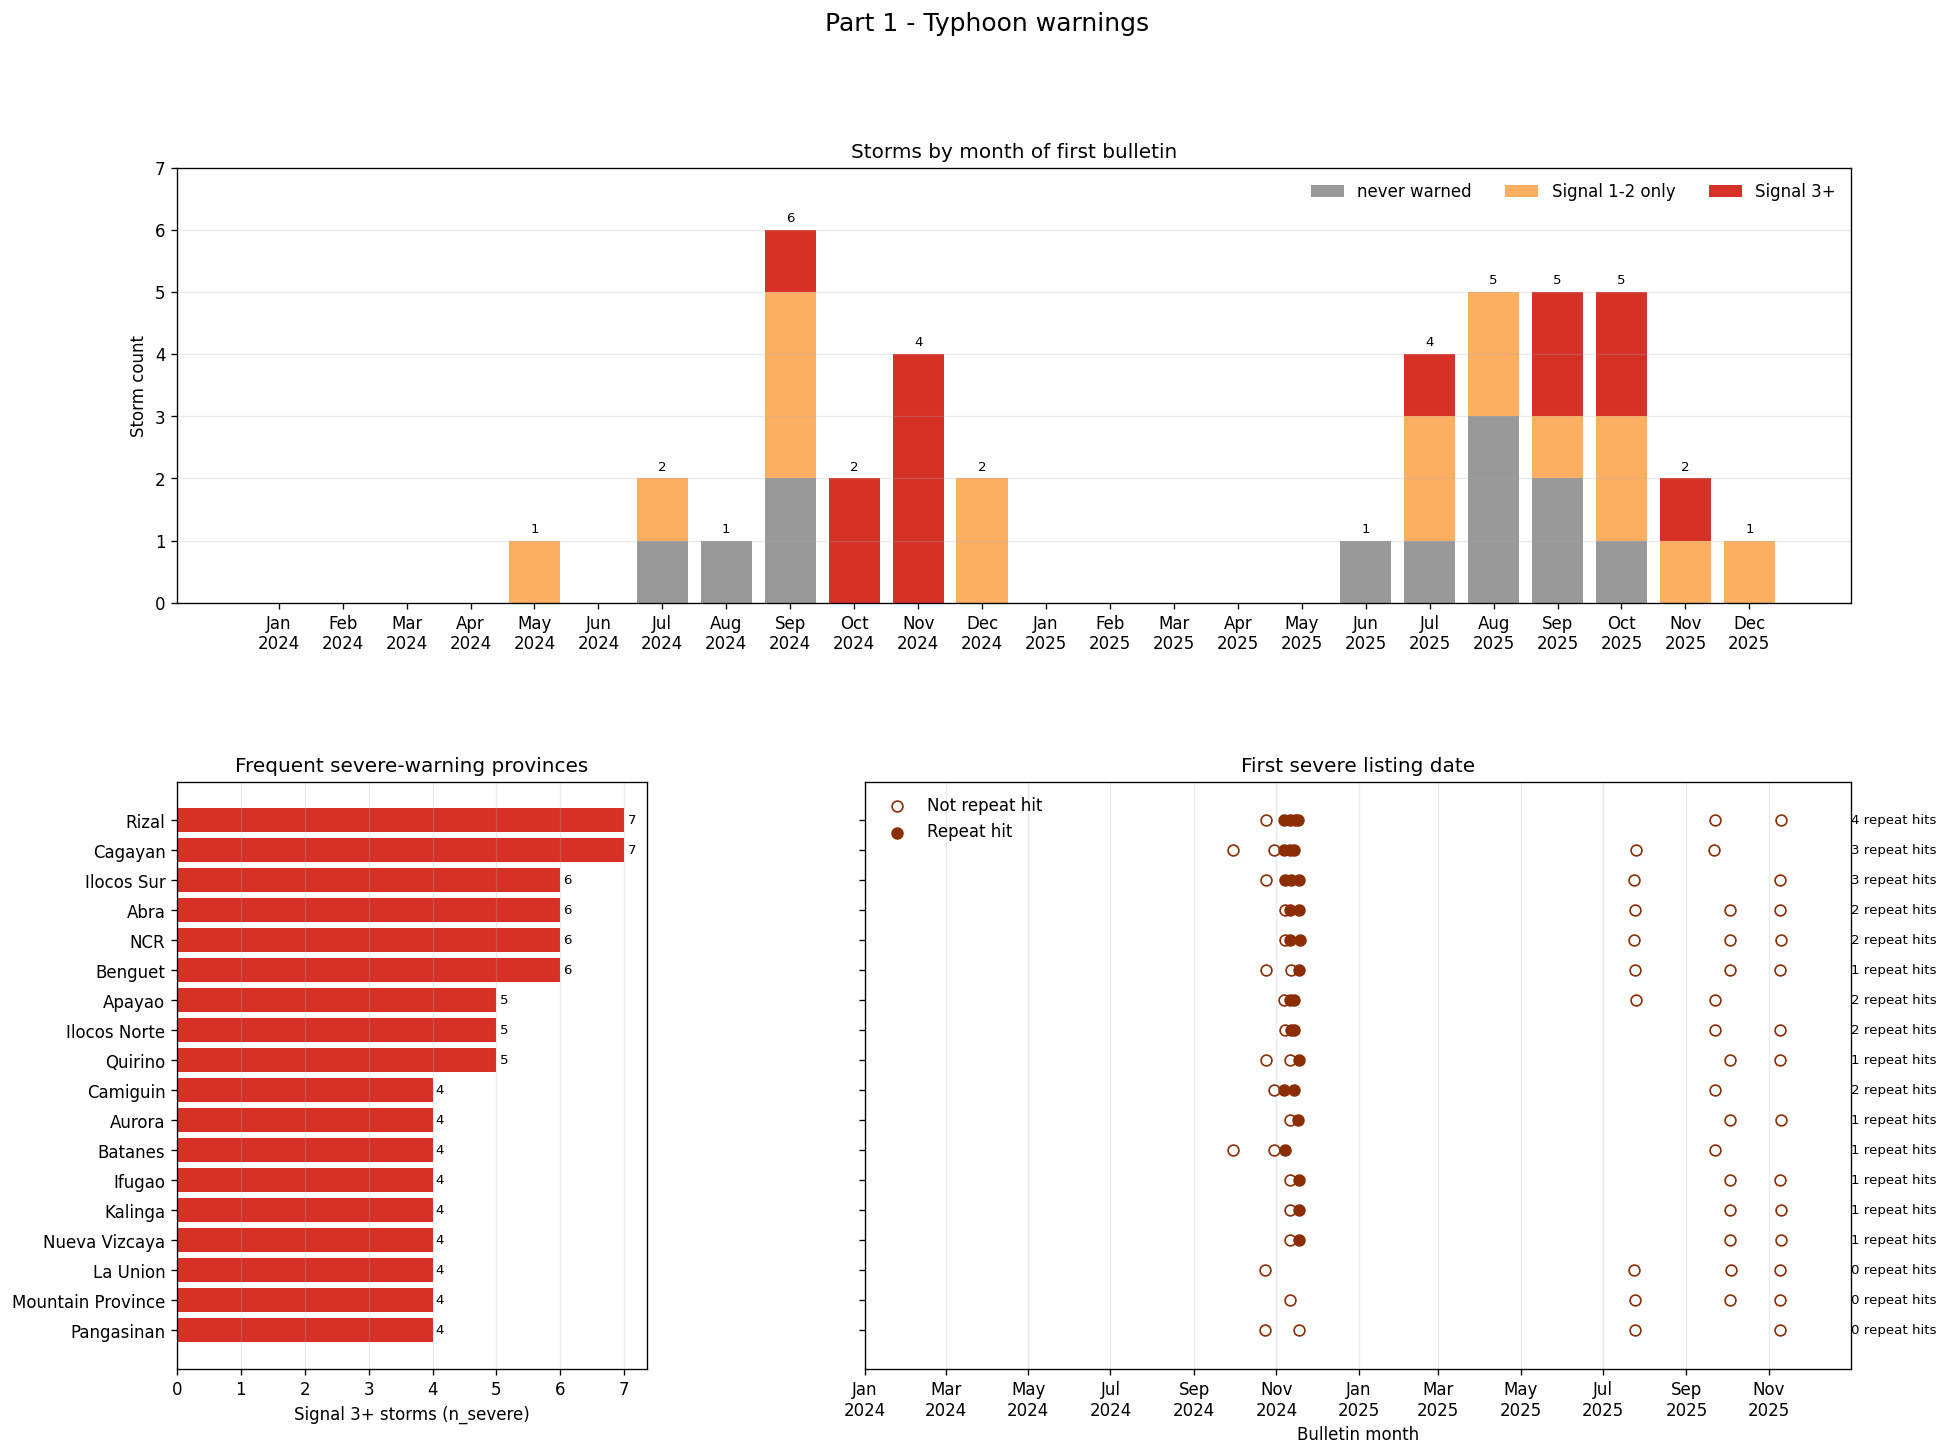

Peak signal counts levels 1-5: [260, 168, 75, 54, 11]
Warned storms: 29 of 41
Total repeat hits across all provinces: 28


In [3]:
from matplotlib.gridspec import GridSpec
fig=plt.figure(figsize=(18,13)); gs=GridSpec(2,2,figure=fig,height_ratios=[1,1.35],width_ratios=[1,2.1],hspace=.35,wspace=.3)
ax_top=fig.add_subplot(gs[0,:]); x=np.arange(len(months)); bottom=np.zeros(len(months)); storm_colors={"never warned":"#999999","Signal 1-2 only":"#fdae61","Signal 3+":"#d73027"}
for typ in ["never warned","Signal 1-2 only","Signal 3+"]:
    vals=storms_by_month[typ].to_numpy(); ax_top.bar(x,vals,bottom=bottom,color=storm_colors[typ],label=typ); bottom+=vals
for i,total in enumerate(bottom.astype(int)):
    if total: ax_top.text(i,total+.08,str(total),ha="center",va="bottom",fontsize=8)
ax_top.set(title="Storms by month of first bulletin",ylabel="Storm count",xticks=x,xticklabels=[m.strftime("%b\n%Y") for m in months]); ax_top.legend(frameon=False,ncol=3); ax_top.grid(axis="y",alpha=.25); ax_top.set_ylim(0,max(bottom)+1)
ax_bar=fig.add_subplot(gs[1,0]); rows=frequent.iloc[::-1]; y=np.arange(len(rows)); ax_bar.barh(y,rows.n_severe,color="#d73027"); ax_bar.set_yticks(y,rows.province); ax_bar.set(xlabel="Signal 3+ storms (n_severe)",title="Frequent severe-warning provinces"); ax_bar.grid(axis="x",alpha=.25)
for yi,(_,r) in zip(y,rows.iterrows()): ax_bar.text(r.n_severe+.05,yi,str(int(r.n_severe)),va="center",fontsize=8)
ax_time=fig.add_subplot(gs[1,1],sharey=ax_bar); ax_time.set_xlim(months.min(),months.max()+pd.offsets.MonthBegin(1)); ax_time.set_yticks(y,rows.province); ax_time.grid(axis="x",alpha=.25)
for yi,(_,r) in zip(y,rows.iterrows()):
    z=first_severe[first_severe.province.eq(r.province)]; ax_time.scatter(z.loc[~z.repeat_hit,"first_severe"],np.full((~z.repeat_hit).sum(),yi),facecolors="white",edgecolors="#8c2d04",s=42,zorder=3,label="Not repeat hit" if yi==0 else None); ax_time.scatter(z.loc[z.repeat_hit,"first_severe"],np.full(z.repeat_hit.sum(),yi),color="#8c2d04",s=42,zorder=4,label="Repeat hit" if yi==0 else None); ax_time.text(months.max()+pd.offsets.MonthBegin(1),yi,f'{int(r.repeat_hits)} repeat hits',va="center",fontsize=8)
ax_time.set(title="First severe listing date",xlabel="Bulletin month"); ax_time.legend(frameon=False,loc="upper left"); ax_time.tick_params(axis="y",labelleft=False); ax_time.set_xticks(months[::2]); ax_time.set_xticklabels([m.strftime("%b\n%Y") for m in months[::2]])
fig.suptitle("Part 1 - Typhoon warnings",fontsize=15); fig.savefig(FIG/"chart1_typhoon_eda.png",bbox_inches="tight"); plt.show()
print("Peak signal counts levels 1-5:",peak.peak_signal.value_counts().reindex(range(1,6),fill_value=0).tolist()); print("Warned storms:",peak.sid.nunique(),"of",signals.sid.nunique()); print("Total repeat hits across all provinces:",int(first_severe.repeat_hit.sum()))

Storms appear in 14 of the 24 months, with no storms recorded from January through April in either year. The lower part of the chart shows that severe-warning exposure was concentrated in a smaller set of provinces, with 28 repeat severe-warning listings across 16 provinces. This gives context for the warning side of the project before the price data are considered. The pattern describes warning records only and does not measure physical damage or explain rice-price changes.


### Descriptive context: rice-price patterns

### Chart 2: price path and regional price swings


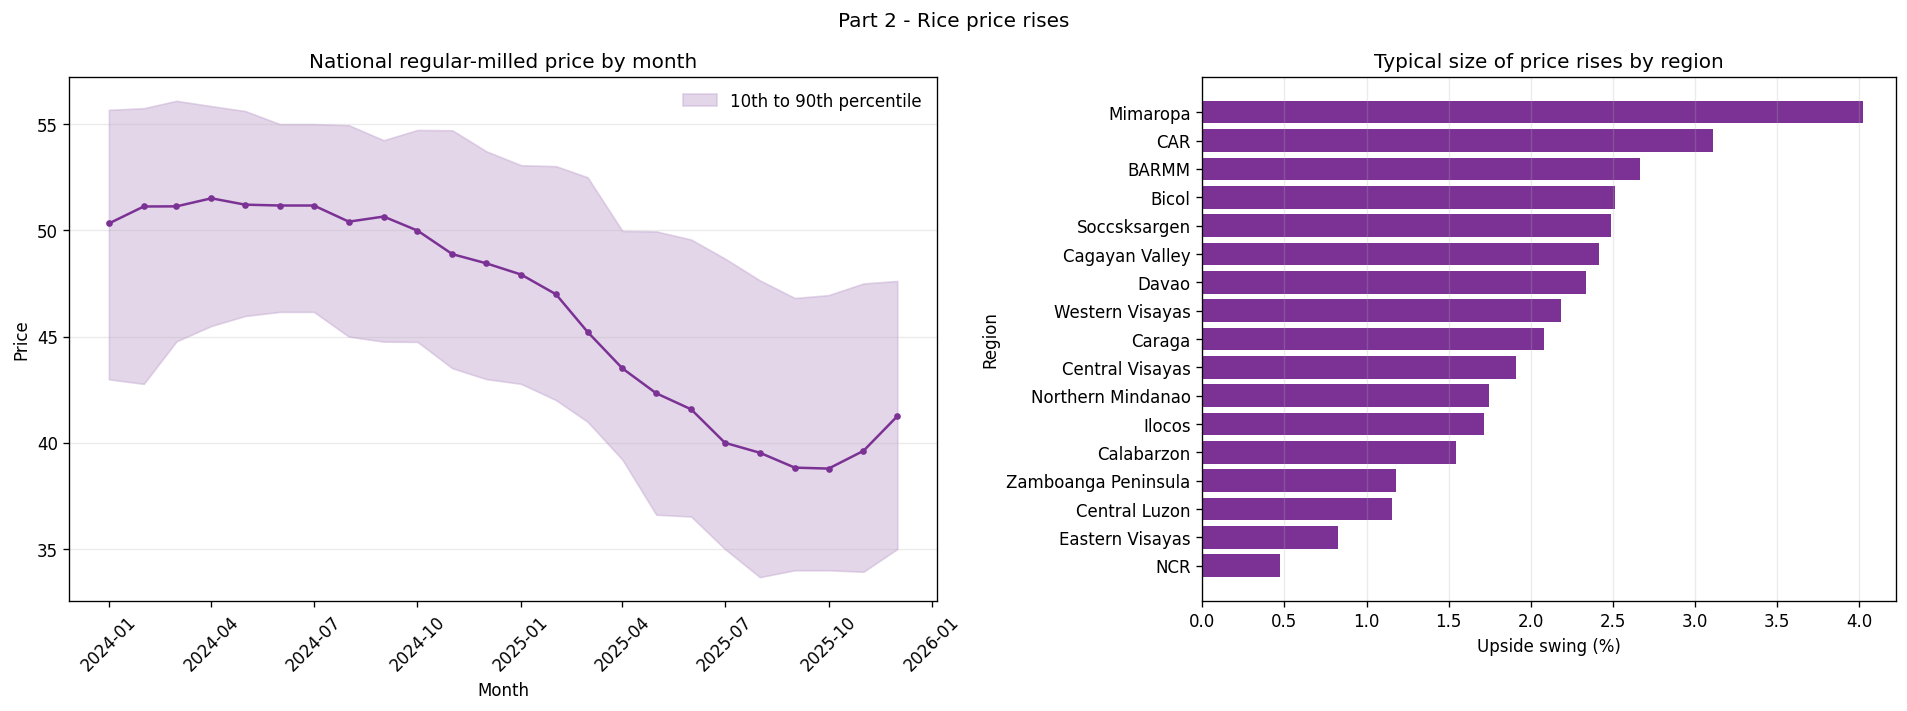

Provinces ending lower: 75 of 81
Median total percent change: -16.89
Missing readings by province: {'Batanes': 48, 'Misamis Occidental': 2, 'Sulu': 48}
Reporting rhythm median/min/max: 0.38 0.0 0.92 | >=0.9: 3
Jan24 median/band: 50.32 42.99 55.67
Oct25 median/band: 38.78 34.0 46.95


In [4]:
mp=pw.dropna(subset=["regular_milled_price"]).assign(month=lambda d:d.period_start.dt.to_period("M").dt.to_timestamp()).groupby("month").regular_milled_price.agg(median="median",p10=lambda x:x.quantile(.1),p90=lambda x:x.quantile(.9)).reindex(months)
fig,ax=plt.subplots(1,2,figsize=(16,6),gridspec_kw={"width_ratios":[1.25,1]}); ax[0].plot(months,mp["median"],color="#7b3294",marker="o",ms=3); ax[0].fill_between(months,mp.p10,mp.p90,color="#c2a5cf",alpha=.45,label="10th to 90th percentile"); ax[0].set(title="National regular-milled price by month",xlabel="Month",ylabel="Price"); ax[0].tick_params(axis="x",rotation=45); ax[0].legend(frameon=False); ax[0].grid(axis="y",alpha=.25)
b=price_stats.groupby("province").size() if False else reg_prices.sort_values("upside_swing"); ax[1].barh(np.arange(len(b)),b.upside_swing,color="#7b3294"); ax[1].set_yticks(np.arange(len(b)),b.region_short); ax[1].set(title="Typical size of price rises by region",xlabel="Upside swing (%)",ylabel="Region"); ax[1].grid(axis="x",alpha=.25); fig.suptitle("Part 2 - Rice price rises"); fig.tight_layout(); fig.savefig(FIG/"chart2_price_eda.png",bbox_inches="tight"); plt.show()
print("Provinces ending lower:",int((price_stats.total_change_pct<0).sum()),"of",len(price_stats)); print("Median total percent change:",round(price_stats.total_change_pct.median(),2)); print("Missing readings by province:",prices.assign(missing=prices.regular_milled_price.isna()).groupby("province").missing.sum().loc[lambda x:x>0].astype(int).to_dict()); print("Reporting rhythm median/min/max:",round(rhythm.median(),2),round(rhythm.min(),2),round(rhythm.max(),2),"| >=0.9:",int((rhythm>=.9).sum())); print("Jan24 median/band:",*[round(mp.loc["2024-01-01",x],2) for x in ["median","p10","p90"]]); print("Oct25 median/band:",*[round(mp.loc["2025-10-01",x],2) for x in ["median","p10","p90"]])


The national price path moves downward overall, while the regional bars show that the size of upward movements differs across regions. Prices ended lower in 75 of 81 provinces, but that broad decline does not mean every province had the same short-term pattern. The chart helps separate the general price direction from the sudden increases used in the project price-swing measure. That distinction is important because the research question is about where larger price increases overlap with severe-warning exposure.


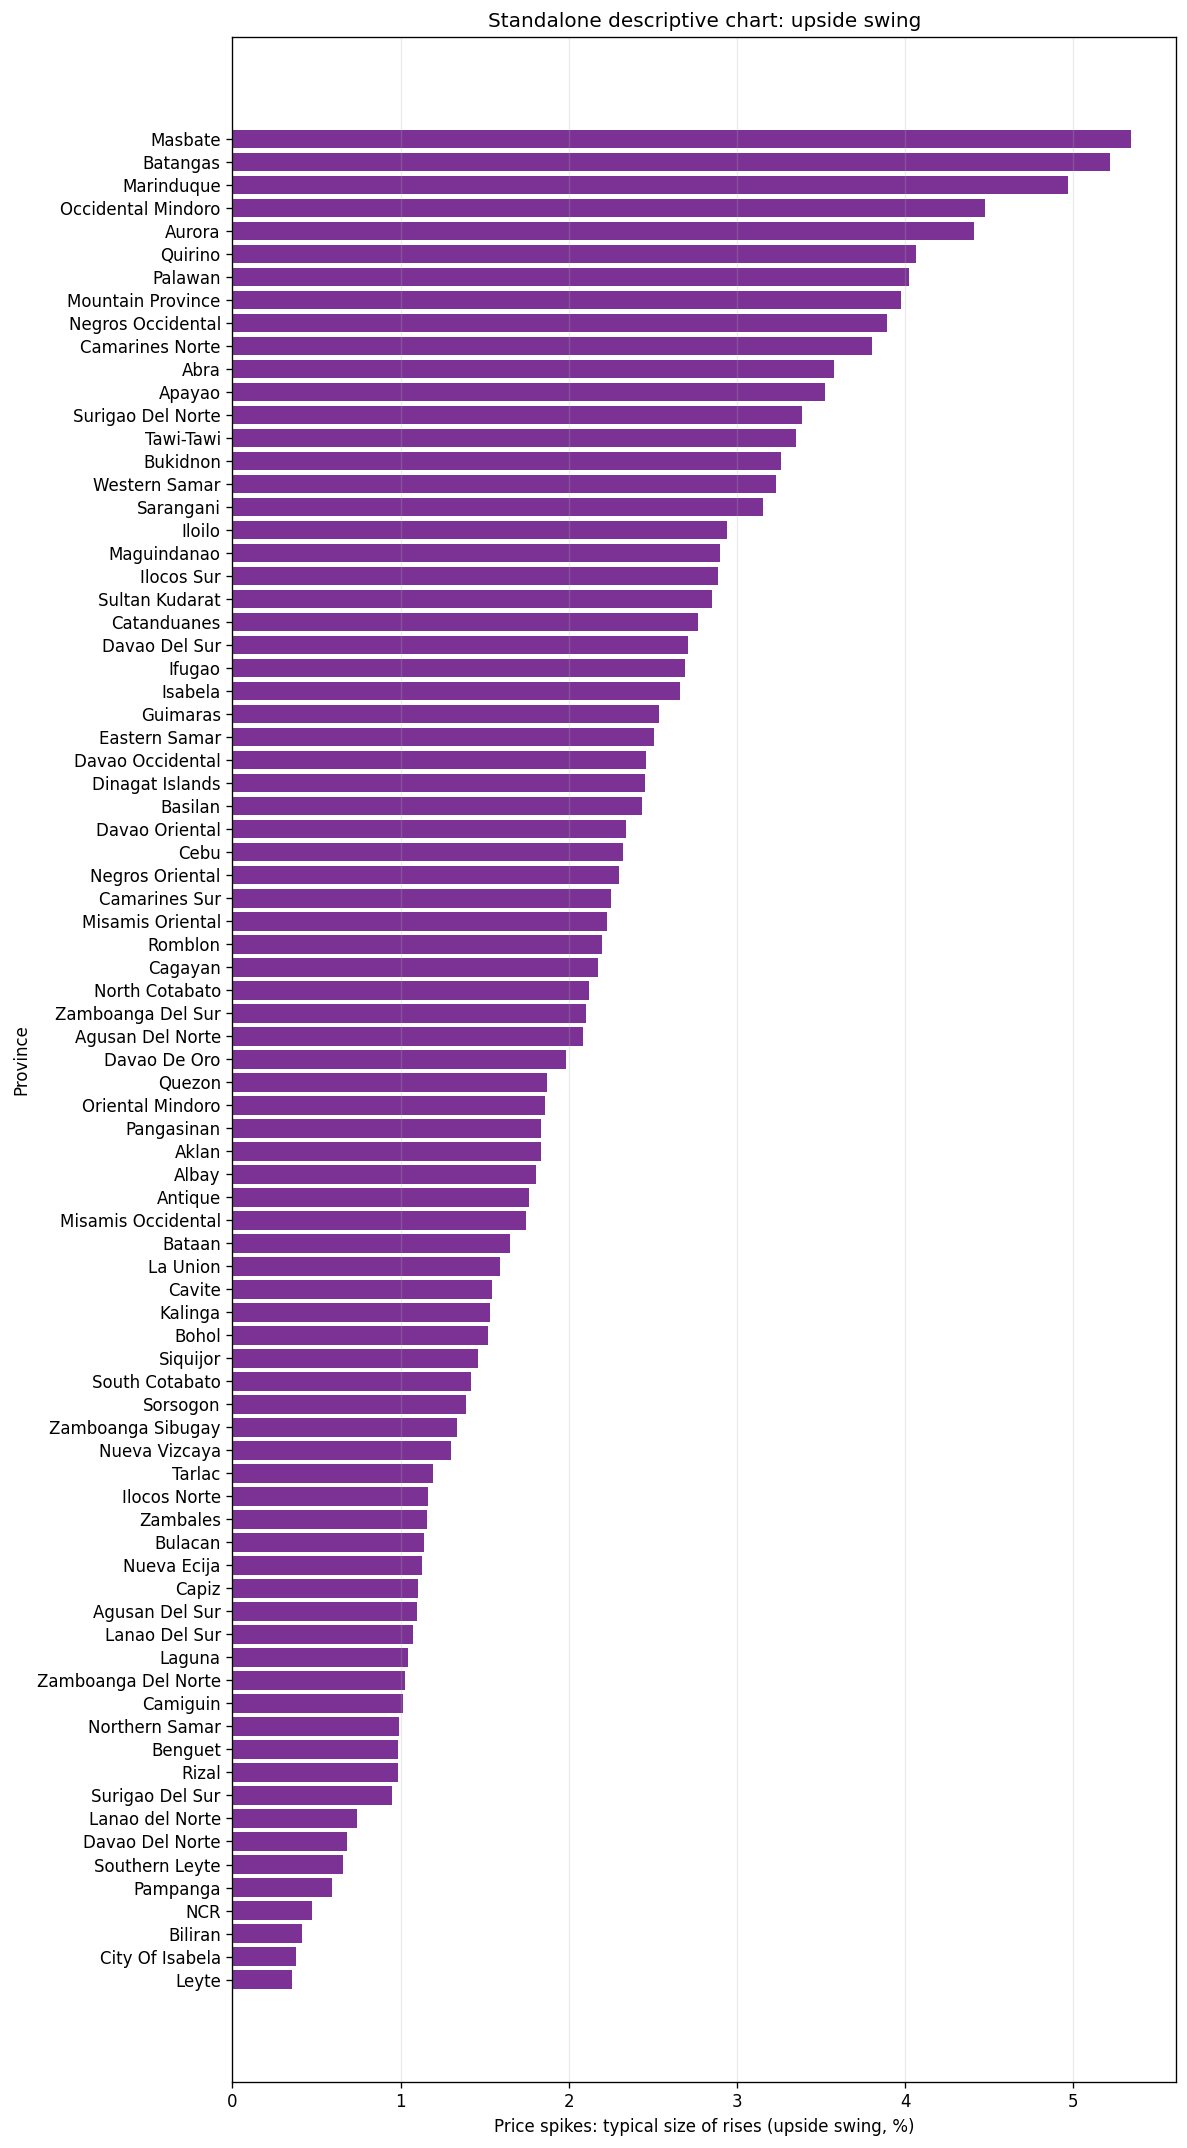

In [5]:
# Standalone descriptive view of upside swing.
bar_data=price_stats.sort_values("upside_swing",ascending=True)
fig,ax=plt.subplots(figsize=(10,18)); ax.barh(bar_data.index,bar_data.upside_swing,color="#7b3294"); ax.set(xlabel="Price spikes: typical size of rises (upside swing, %)",ylabel="Province",title="Standalone descriptive chart: upside swing"); ax.grid(axis="x",alpha=.25); fig.tight_layout(); fig.savefig(FIG/"chart5_upside_swing.png",bbox_inches="tight"); plt.show()


The province ranking shows that Masbate, Batangas, Marinduque, Occidental Mindoro, and Aurora had the largest typical upward rice-price movements in the dataset. Other provinces had smaller or less frequent increases, even though many provinces ended the period at a lower price. This chart shows the specific provinces contributing to the price side of the comparison before warning exposure is added. It helps explain why some provinces later appear in the combined overlap group.


# Segmentation Analysis

### 4. Where the KPIs overlap

We now combine the two KPIs. Each region and province is placed into one of four groups so that the comparison is visible and consistent.

| Group | Meaning in this analysis |
|---|---|
| **Most vulnerable** | High severe-warning exposure and high price swing |
| **Exposed but stable** | High severe-warning exposure and lower price swing |
| **High price swings, lower severe-warning exposure** | Lower severe-warning exposure and high price swing |
| **Low concern** | Lower values on both measures |

**Important:** these labels describe relative values in this dataset. **Most vulnerable** means a place to investigate further; it does not mean proven harm or causation.


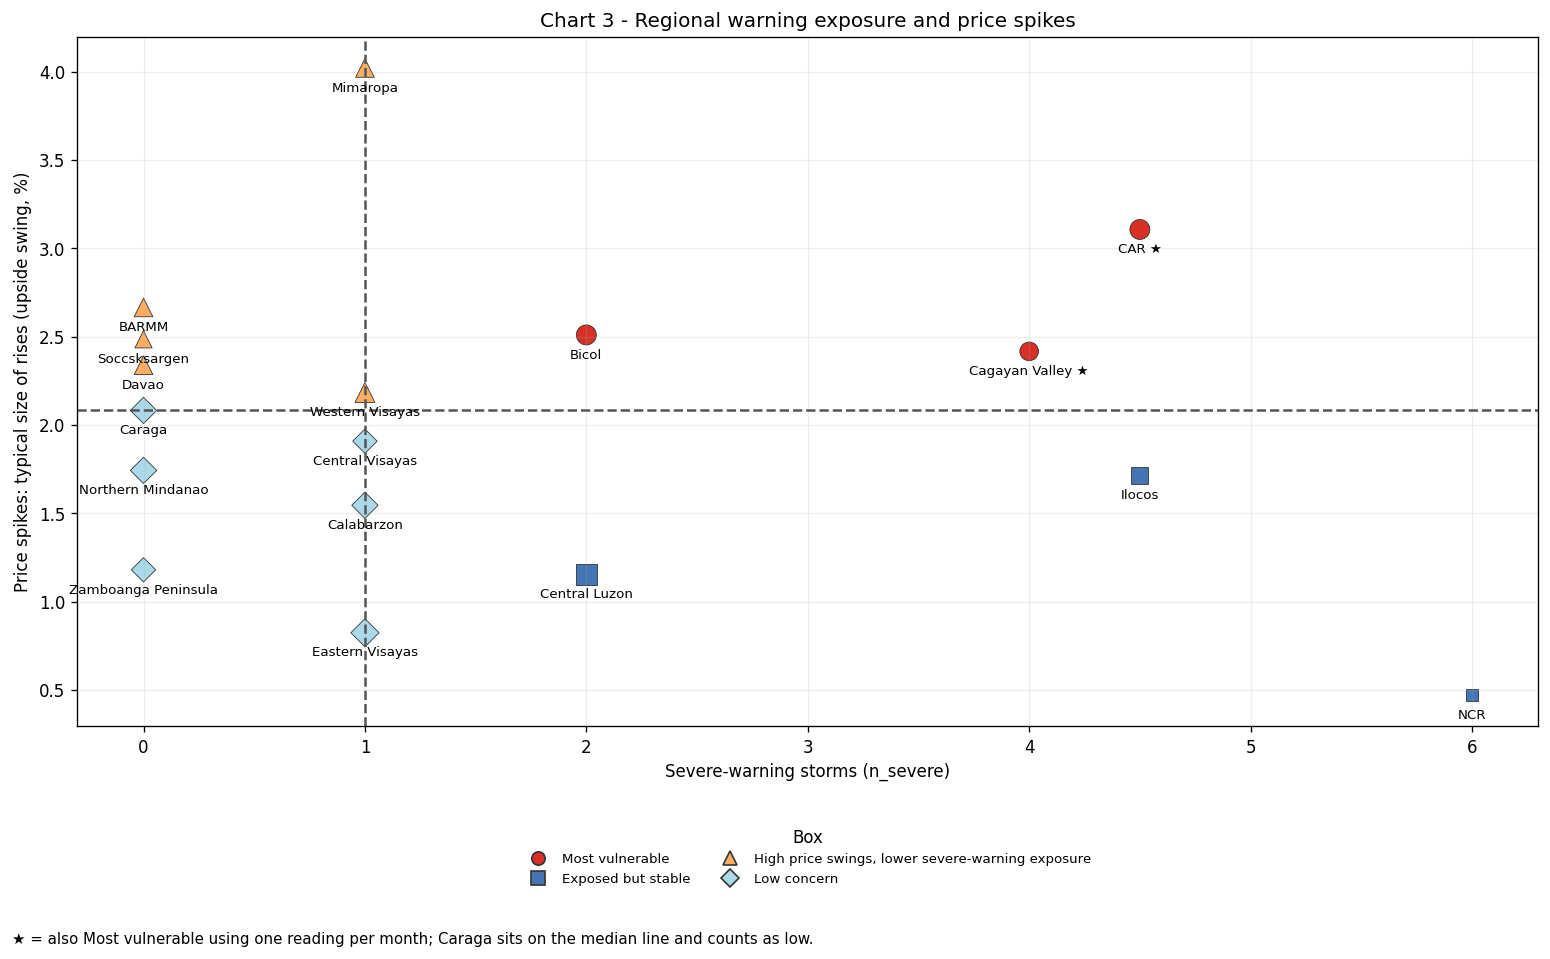

Regional scorecard:
       region_short  n_provinces  n_severe  median_upside_swing                                              box  also_most_vulnerable_monthly
              Bicol            6       2.0             2.509967                                  Most vulnerable                         False
                CAR            6       4.5             3.106921                                  Most vulnerable                          True
     Cagayan Valley            5       4.0             2.416746                                  Most vulnerable                          True
              BARMM            5       0.0             2.665613 High price swings, lower severe-warning exposure                         False
         Calabarzon            5       1.0             1.545492                                      Low concern                         False
             Caraga            5       0.0             2.082374                                      Low concern          

In [6]:
fig,ax=plt.subplots(figsize=(13,8)); ax=ax; ax.set_xlabel("Severe-warning storms (n_severe)"); ax.set_ylabel("Price spikes: typical size of rises (upside swing, %)"); ax.grid(alpha=.2)
for b in BOX:
    z=region_main[region_main.box.eq(b)]; ax.scatter(z.n_severe,z.upside_swing,s=35+18*z.n_provinces,color=COL[b],marker=MARK[b],edgecolor="#333",linewidth=.5)
ax.axvline(region_x_median,color="#555",ls="--"); ax.axhline(region_y_median,color="#555",ls="--"); ax.set_title("Chart 3 - Regional warning exposure and price spikes")
add_labels(ax,region_main,"region_short",only_most=False); legend(ax); fig.text(.01,.01,"\u2605 = also Most vulnerable using one reading per month; Caraga sits on the median line and counts as low.",fontsize=9); fig.tight_layout(rect=[0,0.04,1,1]); fig.savefig(FIG/"chart3_regional_grid.png",bbox_inches="tight"); plt.show()
score=region_main[["region_short","n_provinces","n_severe","upside_swing","box","robust"]].rename(columns={"upside_swing":"median_upside_swing","robust":"also_most_vulnerable_monthly"}).copy(); score["share"]=score.region_short.map(region_shares.share); score["_order"]=score.box.eq("Most vulnerable").map({True:0,False:1}); score=score.sort_values(["_order","region_short"]).drop(columns="_order"); print("Regional scorecard:"); print(score[["region_short","n_provinces","n_severe","median_upside_swing","box","also_most_vulnerable_monthly"]].to_string(index=False)); print("Most vulnerable provinces by region (k/n with price data):"); print(region_shares["share"].to_string()); print("Regional borderline:",region_main.loc[(region_main.upside_swing-region_y_median).abs()<=.01,"region_short"].tolist())

The regional points show how warning exposure and rice-price upside swing vary together across regions. Bicol, CAR, and Cagayan Valley sit in the group that is above both regional medians, making them the clearest regional priorities in this screen. The chart answers the main question by showing where the two patterns overlap rather than looking at either signal alone. These results identify places for closer monitoring, not proof that one pattern caused the other.


### Provincial segmentation

**What it is for:** This chart applies the same comparison to individual provinces.

**What it tells us:** Each point is a province, positioned by severe-warning exposure and rice-price upside swing. Only the overlap-group provinces are labelled so the chart remains readable.

**How it connects to the question:** It identifies the specific provinces behind the regional patterns and shows whether a regional result is broad or concentrated in a smaller number of provinces.

The small sideways movement of points is display-only. It does not change any values or group assignments.


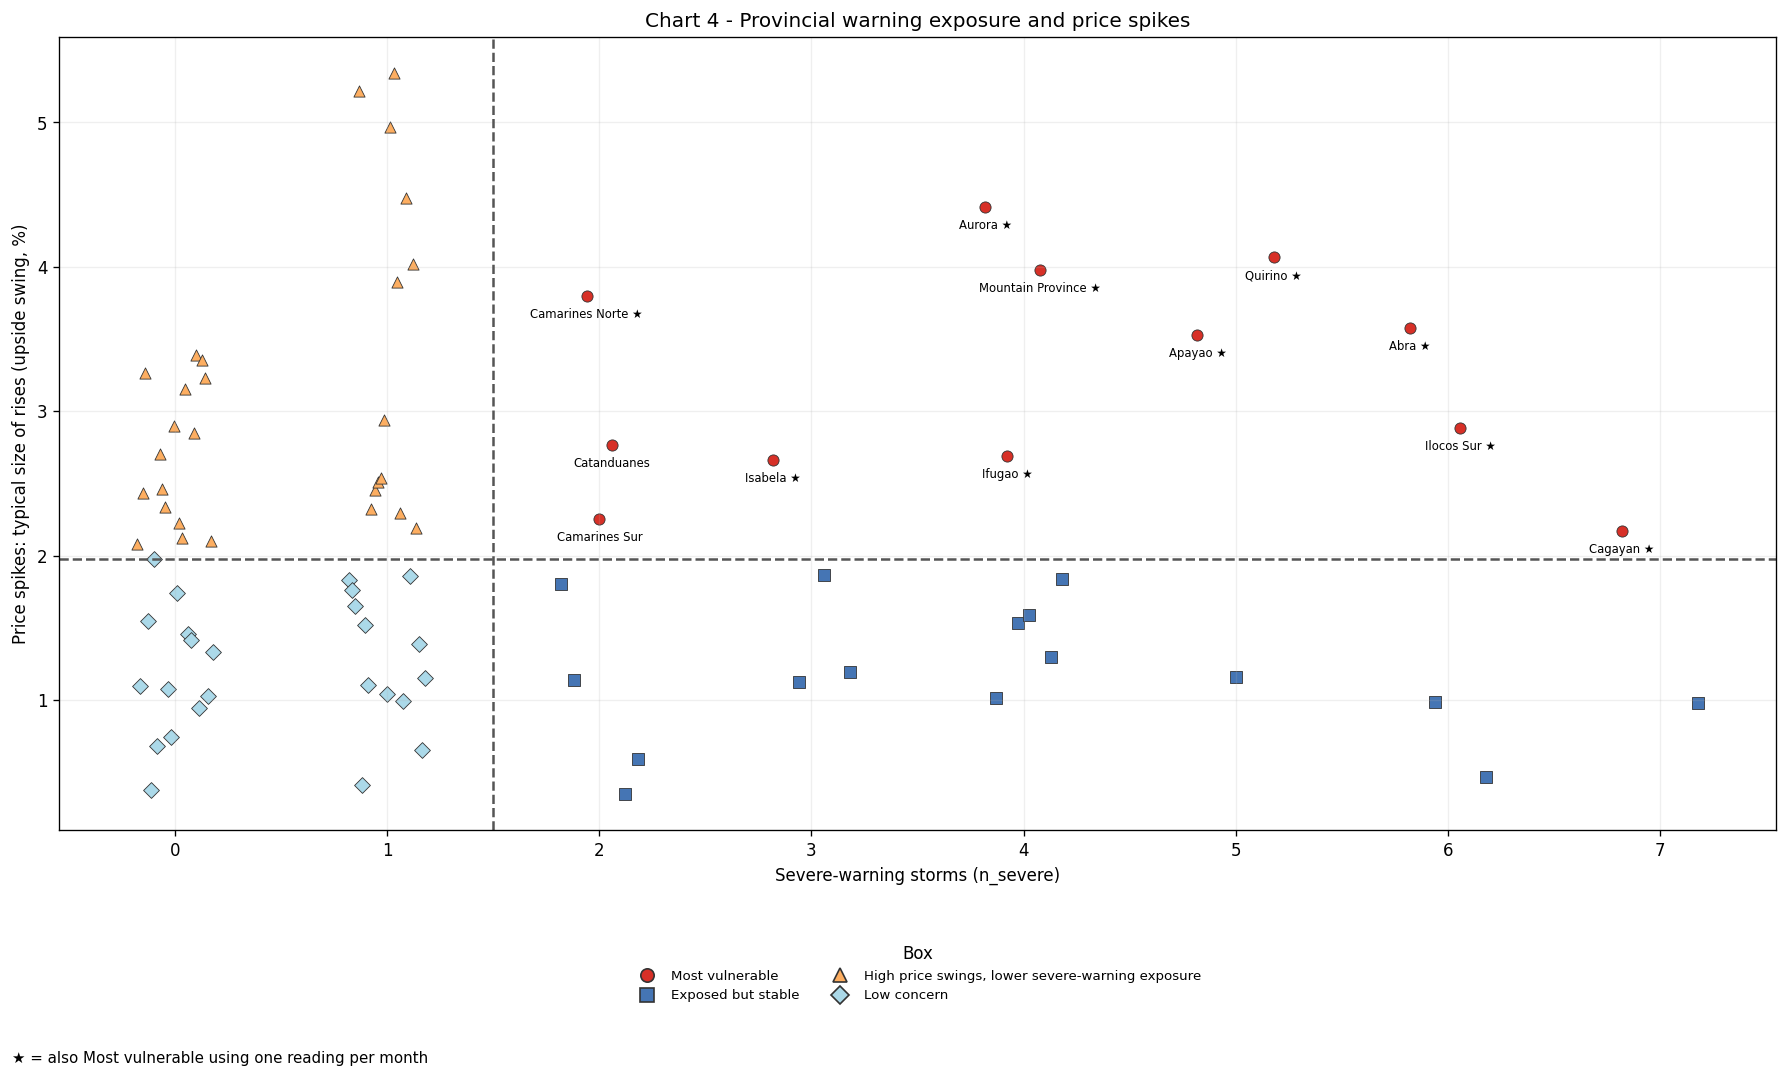

All provinces:
           province        region_short  n_severe upside_swing                                              box  also_most_vulnerable_monthly
            Cagayan      Cagayan Valley         7         2.17                                  Most vulnerable                          True
               Abra                 CAR         6         3.57                                  Most vulnerable                          True
         Ilocos Sur              Ilocos         6         2.89                                  Most vulnerable                          True
             Apayao                 CAR         5         3.53                                  Most vulnerable                          True
            Quirino      Cagayan Valley         5         4.06                                  Most vulnerable                          True
             Aurora       Central Luzon         4         4.41                                  Most vulnerable                      

In [7]:
fig,ax=plt.subplots(figsize=(15,9)); ax.set_xlabel("Severe-warning storms (n_severe)"); ax.set_ylabel("Price spikes: typical size of rises (upside swing, %)"); ax.grid(alpha=.2)
display_positions=display_x(prov_main)
for b in BOX:
    z=prov_main[prov_main.box.eq(b)]; ax.scatter(display_positions.loc[z.index],z.upside_swing,s=45,color=COL[b],marker=MARK[b],edgecolor="#333",linewidth=.5)
ax.axvline(1.5,color="#555",ls="--"); ax.axhline(province_y_median,color="#555",ls="--"); ax.set_title("Chart 4 - Provincial warning exposure and price spikes")
labels=prov_main[prov_main.box.eq("Most vulnerable")].sort_values(["upside_swing","province"])
for idx,r in labels.iterrows():
    suffix=" \u2605" if r.robust else ""; ax.annotate(f"{r.province}{suffix}",(display_positions.loc[idx],r.upside_swing),xytext=(0,-7),textcoords="offset points",ha="center",va="top",fontsize=7)
legend(ax); fig.text(.01,.01,"\u2605 = also Most vulnerable using one reading per month",fontsize=9); fig.tight_layout(rect=[0,0.04,1,1]); fig.savefig(FIG/"chart4_provincial_grid.png",bbox_inches="tight"); plt.show()
province_table=prov_main[["province","region_short","n_severe","upside_swing","box","robust"]].rename(columns={"robust":"also_most_vulnerable_monthly"}); order={b:i for i,b in enumerate(BOX)}; province_table=province_table.assign(_order=province_table.box.map(order)).sort_values(["_order","n_severe","province"],ascending=[True,False,True]).drop(columns="_order"); print("All provinces:"); print(province_table.to_string(index=False,formatters={"upside_swing":"{:.2f}".format})); print("Robustness check summary:"); print("Same box:",int((prov_main.box==prov_main.month_box).sum()),"of",len(prov_main),"provinces"); print("Most vulnerable under one reading per month:",sorted(prov_main.loc[prov_main.month_box.eq("Most vulnerable"),"province"].tolist()))

The provincial points show that the regional overlap is made up of a specific set of provinces rather than a uniform pattern across the country. Twelve provinces are above both medians in the all-reading comparison, including provinces in the Cordillera, Cagayan Valley, and Bicol areas. The chart connects the regional result to concrete places where follow-up monitoring could be focused. The labels are screening results and do not indicate proven damage or causation.


## 4.5 Year-over-year comparison: 2024 versus 2025

The full analysis combines both years to show the overall pattern. This additional chart checks whether the warning and price signals looked similar in 2024 and 2025.

### Chart 6: year-over-year comparison


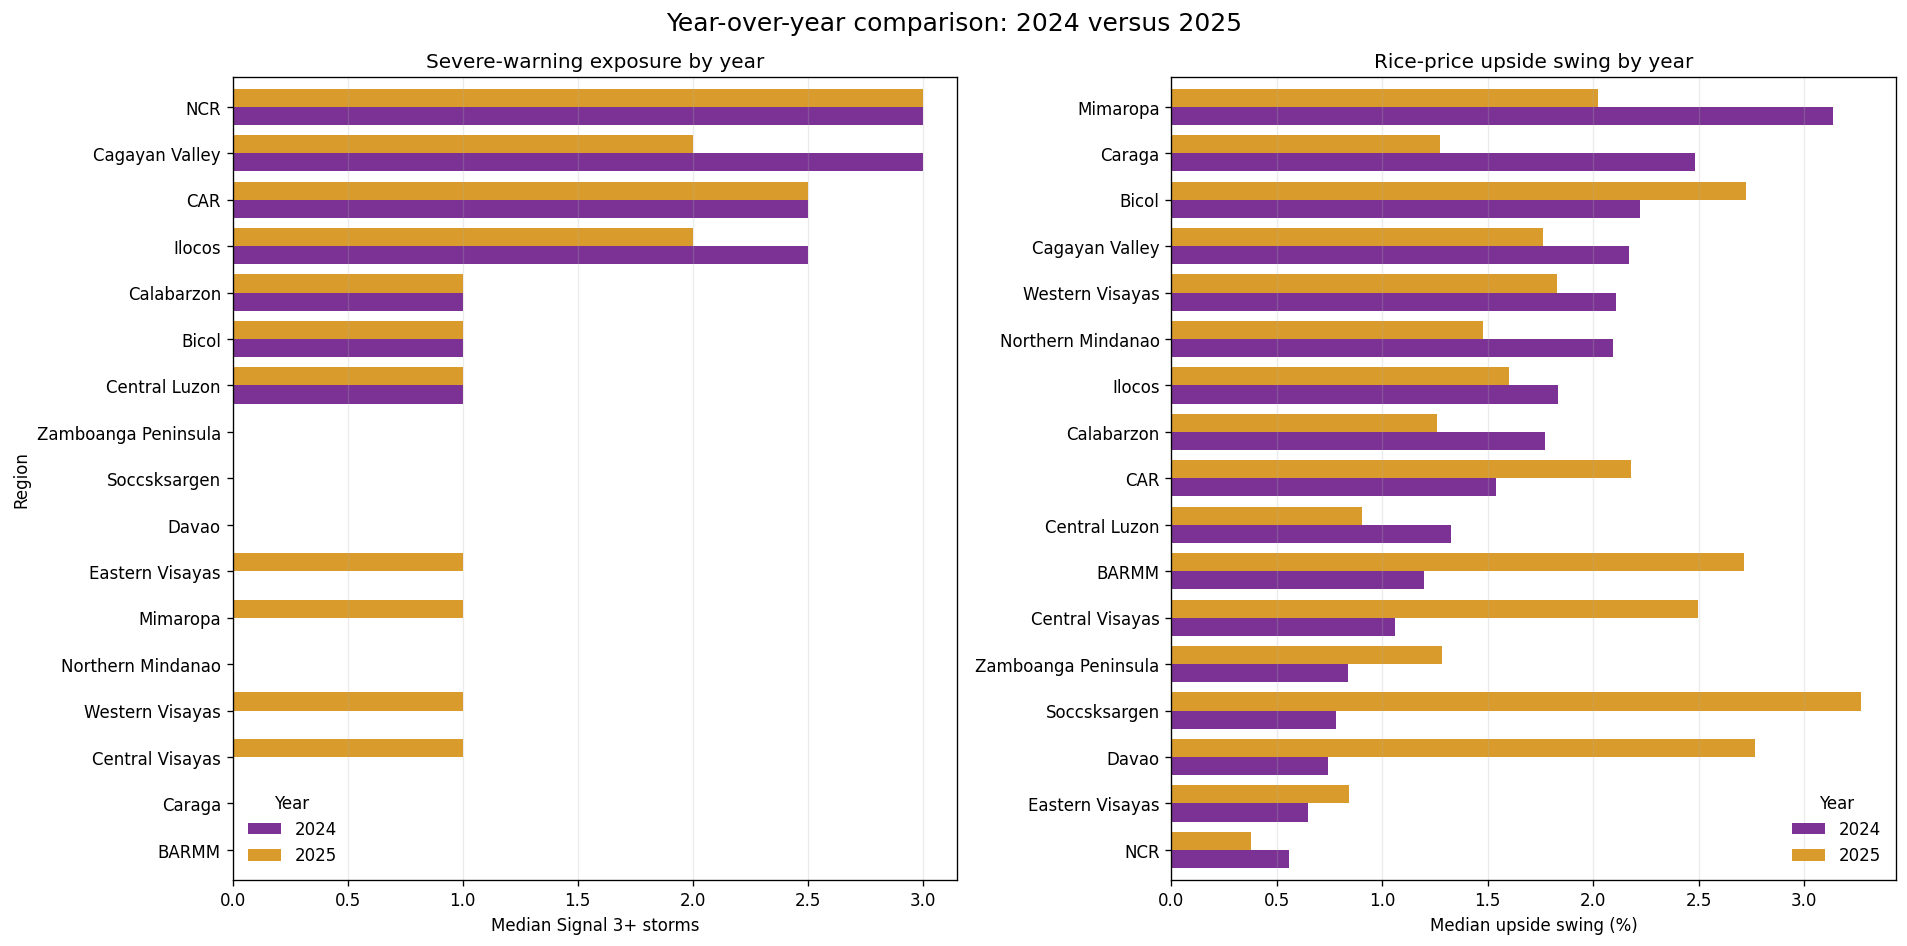

Year-over-year regional comparison:
 season        region_short n_severe upside_swing
   2024               BARMM     0.00         1.20
   2025               BARMM     0.00         2.72
   2024               Bicol     1.00         2.22
   2025               Bicol     1.00         2.72
   2024                 CAR     2.50         1.54
   2025                 CAR     2.50         2.18
   2024      Cagayan Valley     3.00         2.17
   2025      Cagayan Valley     2.00         1.76
   2024          Calabarzon     1.00         1.77
   2025          Calabarzon     1.00         1.26
   2024              Caraga     0.00         2.48
   2025              Caraga     0.00         1.28
   2024       Central Luzon     1.00         1.33
   2025       Central Luzon     1.00         0.91
   2024     Central Visayas     0.00         1.06
   2025     Central Visayas     1.00         2.50
   2024               Davao     0.00         0.75
   2025               Davao     0.00         2.77
   2024     Ea

In [8]:
# Compare the two calendar years using the same province and region definitions.
# Warning exposure is the number of Signal 3+ storms in each year.
yoy_peak = long.groupby(["sid", "season", "province"], as_index=False).signal_level.max()
yoy_exposure = yoy_peak.assign(severe=yoy_peak.signal_level.ge(3)).groupby(["season", "province"], as_index=False).severe.sum().rename(columns={"severe":"n_severe_year"})
yoy_exposure = pd.MultiIndex.from_product([[2024, 2025], all_prov], names=["season", "province"]).to_frame(index=False).merge(yoy_exposure, on=["season", "province"], how="left").fillna({"n_severe_year":0})
yoy_exposure["n_severe_year"] = yoy_exposure["n_severe_year"].astype(int)
yoy_exposure = yoy_exposure.merge(boundaries[["province", "region_short"]], on="province", how="left")

# Calculate each province's upward price movement within each year.
yoy_prices = pw.dropna(subset=["regular_milled_price"]).copy()
yoy_prices["year"] = yoy_prices.period_start.dt.year
yoy_prices["rise_pct"] = yoy_prices.groupby(["province", "year"], group_keys=False).regular_milled_price.pct_change(fill_method=None).mul(100).clip(lower=0).fillna(0)
yoy_price = yoy_prices.groupby(["year", "province"], as_index=False).rise_pct.agg(lambda values: np.sqrt((values.pow(2).sum()) / max(len(values) - 1, 1))).rename(columns={"year":"season", "rise_pct":"upside_swing_year"})
yoy_province = yoy_exposure.merge(yoy_price, on=["season", "province"], how="left")
yoy_province["upside_swing_year"] = yoy_province["upside_swing_year"].fillna(0)
yoy_region = yoy_province.groupby(["season", "region_short"], as_index=False).agg(n_severe=("n_severe_year", "median"), upside_swing=("upside_swing_year", "median"))

fig, ax = plt.subplots(1, 2, figsize=(16, 8), sharey=False)
for axis, value, title, xlabel in [
    (ax[0], "n_severe", "Severe-warning exposure by year", "Median Signal 3+ storms"),
    (ax[1], "upside_swing", "Rice-price upside swing by year", "Median upside swing (%)"),
]:
    plot_data = yoy_region.pivot(index="region_short", columns="season", values=value).sort_values(2024)
    plot_data.plot.barh(ax=axis, color={2024:"#7b3294", 2025:"#d99b2b"}, width=.78)
    axis.set_title(title)
    axis.set_xlabel(xlabel)
    axis.set_ylabel("Region" if axis is ax[0] else "")
    axis.grid(axis="x", alpha=.25)
    axis.legend(title="Year", frameon=False)
fig.suptitle("Year-over-year comparison: 2024 versus 2025", fontsize=15)
fig.tight_layout()
fig.savefig(FIG / "chart6_year_over_year.png", bbox_inches="tight")
plt.show()

print("Year-over-year regional comparison:")
print(yoy_region.sort_values(["region_short", "season"]).to_string(index=False, formatters={"n_severe":"{:.2f}".format, "upside_swing":"{:.2f}".format}))


The year-over-year chart shows that warning exposure and rice-price upside swing do not move in exactly the same way across all regions. Some regions have higher price swings in 2025, while others are higher in 2024; warning exposure also changes by region and year. This helps show whether the overall overlap is persistent or concentrated in a particular calendar year. The differences are descriptive and may reflect different storms, market conditions, or reporting coverage, so they do not establish causation.


## 5. How confident should we be?

We repeat the price-swing calculation using one reading per month. This tests whether the broad pattern depends too heavily on the twice-monthly reporting schedule.

This is a descriptive stability check, not a statistical significance test.


In [9]:
print("Robustness check summary:"); print("Same box: regions",int((region_main.box==region_main.month_box).sum()),"of",len(region_main),"; provinces",int((prov_main.box==prov_main.month_box).sum()),"of",len(prov_main)); print("Most vulnerable regions under one reading per month:",sorted(region_main.loc[region_main.month_box.eq("Most vulnerable"),"region_short"].tolist())); print("Most vulnerable provinces under one reading per month:",sorted(prov_main.loc[prov_main.month_box.eq("Most vulnerable"),"province"].tolist())); print("Most vulnerable provinces under both versions:",sorted(prov_main.loc[prov_main.box.eq("Most vulnerable")&prov_main.month_box.eq("Most vulnerable"),"province"].tolist()))
print("Province box counts:",prov_main.box.value_counts().reindex(BOX).tolist(),"| expected [12, 16, 28, 25]"); print("Province monthly box counts:",prov_main.month_box.value_counts().reindex(BOX).tolist(),"| expected [13, 15, 27, 26]"); print("Region median n_severe/upside:",region_x_median,round(region_y_median,2),"| expected 1.0/2.08"); print("Region box counts:",region_main.box.value_counts().reindex(BOX).tolist(),"| expected [3, 3, 5, 6]"); print("Region monthly median upside/box counts:",round(region_month_y_median,2),region_month.box.value_counts().reindex(BOX).tolist(),"| expected 2.15/[2, 4, 6, 5]"); print("Most vulnerable regions all readings:",sorted(region_main.loc[region_main.box.eq("Most vulnerable"),"region_short"].tolist())); print("Most vulnerable provinces all readings:",sorted(prov_main.loc[prov_main.box.eq("Most vulnerable"),"province"].tolist()))

Robustness check summary:
Same box: regions 13 of 17 ; provinces 67 of 81
Most vulnerable regions under one reading per month: ['CAR', 'Cagayan Valley']
Most vulnerable provinces under one reading per month: ['Abra', 'Apayao', 'Aurora', 'Cagayan', 'Camarines Norte', 'Ifugao', 'Ilocos Norte', 'Ilocos Sur', 'Isabela', 'Kalinga', 'Mountain Province', 'Quezon', 'Quirino']
Most vulnerable provinces under both versions: ['Abra', 'Apayao', 'Aurora', 'Cagayan', 'Camarines Norte', 'Ifugao', 'Ilocos Sur', 'Isabela', 'Mountain Province', 'Quirino']
Province box counts: [12, 16, 28, 25] | expected [12, 16, 28, 25]
Province monthly box counts: [13, 15, 27, 26] | expected [13, 15, 27, 26]
Region median n_severe/upside: 1.0 2.08 | expected 1.0/2.08
Region box counts: [3, 3, 5, 6] | expected [3, 3, 5, 6]
Region monthly median upside/box counts: 2.15 [2, 4, 6, 5] | expected 2.15/[2, 4, 6, 5]
Most vulnerable regions all readings: ['Bicol', 'CAR', 'Cagayan Valley']
Most vulnerable provinces all readings:

### What the data supports

- The two KPIs can be used to screen regions and provinces together.
- The overlap group identifies places with relatively high values on both measures.
- 67 of 81 provinces and 13 of 17 regions keep the same group under the monthly check.
- The results can guide monitoring and identify questions for deeper research.

### What the data does not support

- It does not prove that typhoons caused rice-price increases.
- It does not measure storm damage, household impact, or recovery.
- It does not rule out transport, supply, demand, policy, or other explanations.
